# 05 — Détection d'anomalies (Isolation Forest) et Health Score

## Objectif du notebook

1. Détecter les **comportements inhabituels** des moteurs avec un algorithme **non supervisé** :
   **Isolation Forest**.
2. Construire un **score d'anomalie** compréhensible (0 à 1).
3. Combiner le RUL prédit et le score d'anomalie dans un **Health Score** (0 à 100).
4. Sauvegarder le modèle (`anomaly_model.pkl`) et compléter `metrics.json`.

## 1. Principe d'Isolation Forest

L'idée est simple : **une observation anormale est facile à isoler**.

- L'algorithme construit des arbres en choisissant **au hasard** une variable puis une valeur de coupure.
- Une observation « normale », entourée de beaucoup d'autres, nécessite **beaucoup de coupures** pour être isolée.
- Une observation « inhabituelle », éloignée des autres, est isolée en **peu de coupures**.

La longueur moyenne du chemin dans les arbres donne un **score d'anomalie** $s \in (0, 1]$
(Liu et al., 2008) :
- $s$ proche de **1** → observation très inhabituelle ;
- $s$ nettement **inférieur à 0,5** → observation normale.

Dans scikit-learn, ce score s'obtient avec `-model.score_samples(X)`.

**Remarque :** Isolation Forest coupe chaque variable entre son minimum et son maximum :
il n'est donc **pas sensible à l'échelle** des variables, aucune normalisation n'est nécessaire.

## 2. Importations et données

In [1]:
# Importation des bibliothèques
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import IsolationForest

sys.path.append("../backend")
from features import (get_anomaly_columns, normalize_anomaly_score, compute_health_score,
                      get_machine_state, HEALTH_RUL_WEIGHT, HEALTH_ANOMALY_WEIGHT,
                      NORMAL_THRESHOLD, CRITICAL_THRESHOLD, MAX_RUL)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 90
RANDOM_STATE = 42

In [2]:
train_set = pd.read_csv("../data/processed/train_set.csv")
validation_set = pd.read_csv("../data/processed/validation_set.csv")

# Variables utilisées : moyennes mobiles des 14 capteurs (moins bruitées)
anomaly_columns = get_anomaly_columns()
print("Variables utilisées :", anomaly_columns)

Variables utilisées : ['sensor_2_mean', 'sensor_3_mean', 'sensor_4_mean', 'sensor_7_mean', 'sensor_8_mean', 'sensor_9_mean', 'sensor_11_mean', 'sensor_12_mean', 'sensor_13_mean', 'sensor_14_mean', 'sensor_15_mean', 'sensor_17_mean', 'sensor_20_mean', 'sensor_21_mean']


## 3. Définition d'une référence de fonctionnement sain

Le dataset **ne contient pas d'étiquettes d'anomalies**. On définit donc une référence :
les cycles des moteurs d'entraînement dont le RUL est **au plateau (≥ 125 cycles)**,
c'est-à-dire en début de vie, quand le moteur est en bonne santé.

Isolation Forest apprend ce comportement sain ; tout écart sera considéré comme inhabituel.

In [3]:
healthy_data = train_set[train_set["RUL"] >= MAX_RUL]
print("Observations saines de référence :", len(healthy_data), "sur", len(train_set))

X_healthy = healthy_data[anomaly_columns]

Observations saines de référence : 6340 sur 16340


## 4. Entraînement d'Isolation Forest

| Paramètre | Valeur | Rôle |
|---|---|---|
| `n_estimators` | 200 | nombre d'arbres d'isolation |
| `contamination` | 0.02 | on accepte que 2 % des observations saines dépassent le seuil (fausses alertes) |
| `random_state` | 42 | reproductibilité |

In [4]:
anomaly_model = IsolationForest(n_estimators=200, contamination=0.02, random_state=RANDOM_STATE)
anomaly_model.fit(X_healthy)

# Seuil de décision sur le score s (au-dessus → anomalie)
anomaly_threshold = -anomaly_model.offset_
print("Seuil du score d'anomalie : %.4f" % anomaly_threshold)

Seuil du score d'anomalie : 0.5535


## 5. Calcul du score d'anomalie et détection

In [5]:
# Score brut s pour toutes les observations de validation
validation_set["anomaly_raw"] = -anomaly_model.score_samples(validation_set[anomaly_columns])

# Détection : predict() renvoie -1 pour une anomalie et 1 pour une observation normale
validation_set["is_anomaly"] = anomaly_model.predict(validation_set[anomaly_columns]) == -1

print("Proportion d'anomalies détectées (validation) : %.1f %%"
      % (100 * validation_set["is_anomaly"].mean()))

Proportion d'anomalies détectées (validation) : 29.9 %


rul_range
0-25       100.0
25-50       82.0
50-75       39.2
75-100      18.8
100-125      3.6
Name: is_anomaly, dtype: float64


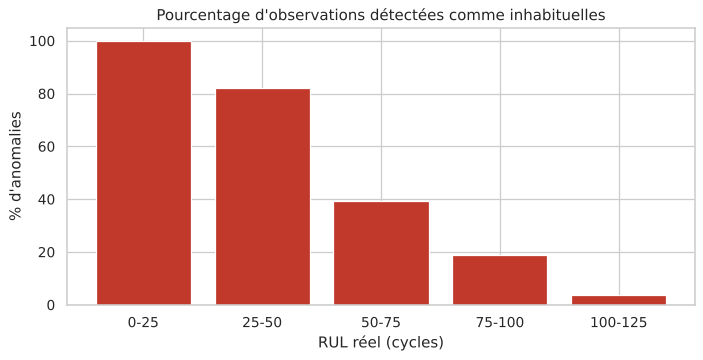

In [6]:
# Proportion d'anomalies selon la proximité de la panne
rul_bins = [0, 25, 50, 75, 100, 126]
rul_labels = ["0-25", "25-50", "50-75", "75-100", "100-125"]
validation_set["rul_range"] = pd.cut(validation_set["RUL"], bins=rul_bins,
                                     labels=rul_labels, right=False)

anomaly_rate = validation_set.groupby("rul_range", observed=False)["is_anomaly"].mean() * 100
print(anomaly_rate.round(1))

plt.figure(figsize=(9, 4))
plt.bar(anomaly_rate.index.astype(str), anomaly_rate.values, color="#c0392b")
plt.title("Pourcentage d'observations détectées comme inhabituelles")
plt.xlabel("RUL réel (cycles)")
plt.ylabel("% d'anomalies")
plt.show()

**Interprétation :** la proportion d'observations inhabituelles augmente fortement quand le moteur
approche de la panne, alors que le modèle n'a **jamais vu le RUL** pendant son apprentissage :
il ne connaît que le comportement sain. La détection est donc cohérente avec la dégradation.

## 6. Visualisation des observations normales et inhabituelles

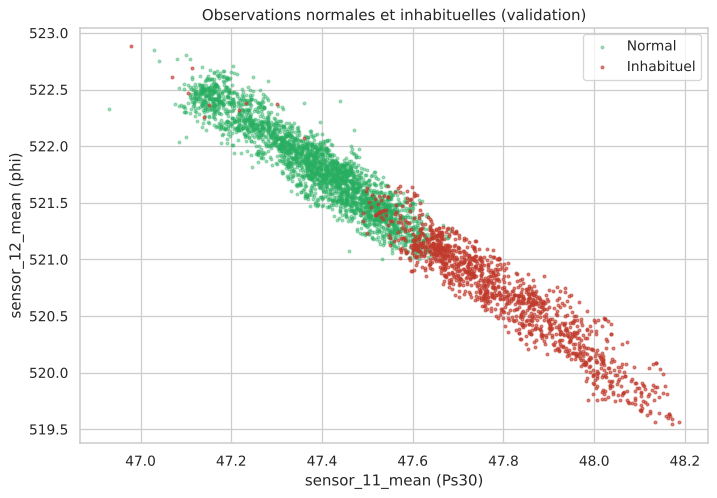

In [7]:
plt.figure(figsize=(9, 6))
normal_points = validation_set[~validation_set["is_anomaly"]]
abnormal_points = validation_set[validation_set["is_anomaly"]]
plt.scatter(normal_points["sensor_11_mean"], normal_points["sensor_12_mean"],
            s=5, alpha=0.4, color="#27ae60", label="Normal")
plt.scatter(abnormal_points["sensor_11_mean"], abnormal_points["sensor_12_mean"],
            s=5, alpha=0.6, color="#c0392b", label="Inhabituel")
plt.xlabel("sensor_11_mean (Ps30)")
plt.ylabel("sensor_12_mean (phi)")
plt.title("Observations normales et inhabituelles (validation)")
plt.legend()
plt.show()

## 7. Score d'anomalie normalisé (compréhensible dans l'application)

Le score brut $s$ varie dans une petite plage (environ 0,35 à 0,75), difficile à lire.
On le transforme en **niveau d'anomalie entre 0 et 1** à partir de deux références calculées
**sur les moteurs d'entraînement** :

- `healthy_reference` = médiane de $s$ sur les cycles sains (RUL ≥ 125) ;
- `failure_reference` = médiane de $s$ sur les 10 derniers cycles avant la panne (RUL ≤ 10).

$$\text{niveau d'anomalie} = \text{clip}\left(\frac{s - s_{sain}}{s_{panne} - s_{sain}},\ 0,\ 1\right)$$

- **0** : comportement identique à un moteur sain ;
- **1** : comportement identique à un moteur juste avant la panne.

In [8]:
train_scores = -anomaly_model.score_samples(train_set[anomaly_columns])
healthy_reference = float(np.median(train_scores[train_set["RUL"].values >= MAX_RUL]))
failure_reference = float(np.median(train_scores[train_set["RUL"].values <= 10]))

print("Référence saine   : %.4f" % healthy_reference)
print("Référence de panne : %.4f" % failure_reference)

# Application de la normalisation à la validation
anomaly_levels = []
for raw_score in validation_set["anomaly_raw"]:
    anomaly_levels.append(normalize_anomaly_score(raw_score, healthy_reference, failure_reference))
validation_set["anomaly_level"] = anomaly_levels

Référence saine   : 0.4505
Référence de panne : 0.7005


## 8. Évolution du score d'anomalie au cours du temps

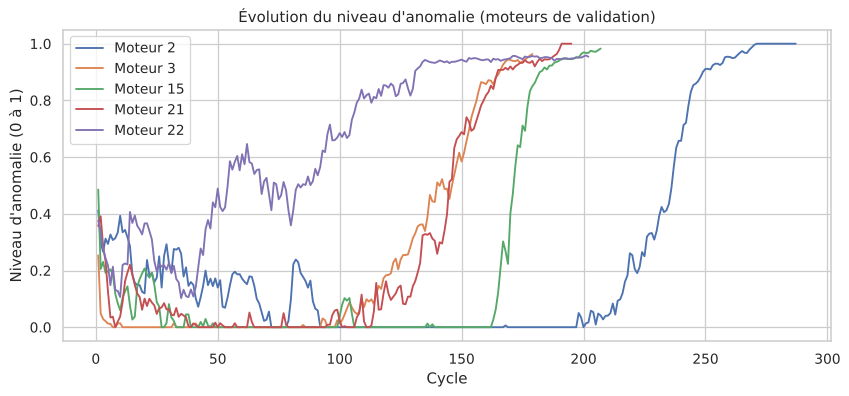

In [9]:
example_engines = validation_set["unit_id"].unique()[:5]

plt.figure(figsize=(11, 4.5))
for engine in example_engines:
    engine_data = validation_set[validation_set["unit_id"] == engine]
    plt.plot(engine_data["cycle"], engine_data["anomaly_level"], label="Moteur " + str(engine))
plt.title("Évolution du niveau d'anomalie (moteurs de validation)")
plt.xlabel("Cycle")
plt.ylabel("Niveau d'anomalie (0 à 1)")
plt.legend()
plt.show()

**Interprétation :** le niveau d'anomalie reste proche de 0 pendant la majeure partie de la vie
du moteur, puis augmente progressivement à l'approche de la panne.

### Limite importante
Le dataset ne contient **aucune étiquette d'anomalie** (on ne sait pas quel cycle est « anormal »).
Il est donc **impossible de calculer honnêtement** une Accuracy, une Precision, un Recall ou un F1-score.
L'évaluation reste **qualitative** : cohérence entre le score et la proximité de la panne.

## 9. Health Score

Le Health Score combine les deux modèles dans un indicateur unique entre 0 et 100 :

$$\text{Health Score} = 100 \times \left(0{,}7 \times \frac{\min(\hat{RUL}, 125)}{125}
  + 0{,}3 \times (1 - \text{niveau d'anomalie})\right)$$

| Élément | Explication |
|---|---|
| $\min(\hat{RUL}, 125)/125$ | RUL prédit normalisé entre 0 et 1 |
| $1 - \text{niveau d'anomalie}$ | 1 si le comportement est sain, 0 s'il ressemble à une panne |
| **0,7** | le RUL est l'information principale (modèle supervisé, évalué quantitativement) |
| **0,3** | l'anomalie apporte un signal complémentaire, non supervisé |

**États :**
- 🟢 **Normal** : Health Score ≥ 70
- 🟠 **Avertissement** : 30 ≤ Health Score < 70
- 🔴 **Critique** : Health Score < 30

⚠️ Le Health Score est un **indicateur pédagogique d'aide à la décision**,
et non un indicateur industriel certifié.

In [10]:
# Prédiction du RUL sur la validation avec le modèle final
preprocessing = joblib.load("../models/preprocessing.pkl")
rul_model = joblib.load("../models/rul_model.pkl")
X_validation = preprocessing["scaler"].transform(validation_set[preprocessing["feature_columns"]])
validation_set["predicted_rul"] = np.clip(rul_model.predict(X_validation), 0, None)

# Calcul du Health Score et de l'état ligne par ligne
health_scores = []
states = []
for index in range(len(validation_set)):
    predicted_rul = validation_set["predicted_rul"].iloc[index]
    anomaly_level = validation_set["anomaly_level"].iloc[index]
    health_score = compute_health_score(predicted_rul, anomaly_level)
    health_scores.append(health_score)
    states.append(get_machine_state(health_score))

validation_set["health_score"] = health_scores
validation_set["state"] = states

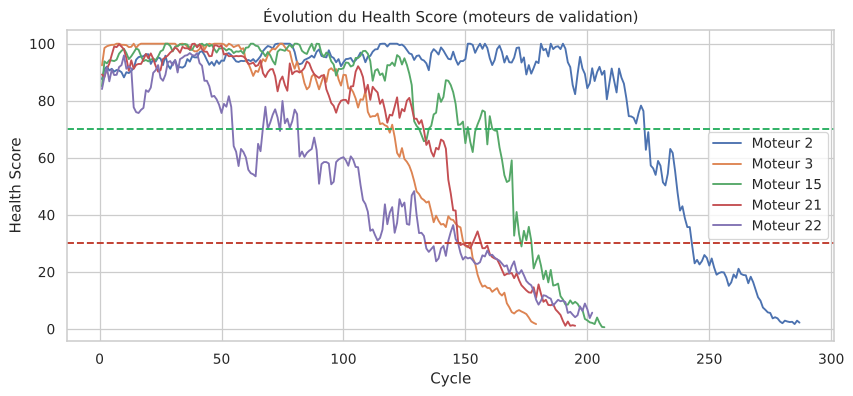

In [11]:
# Évolution du Health Score pour quelques moteurs
plt.figure(figsize=(11, 4.5))
for engine in example_engines:
    engine_data = validation_set[validation_set["unit_id"] == engine]
    plt.plot(engine_data["cycle"], engine_data["health_score"], label="Moteur " + str(engine))
plt.axhline(NORMAL_THRESHOLD, color="#27ae60", linestyle="--")
plt.axhline(CRITICAL_THRESHOLD, color="#c0392b", linestyle="--")
plt.title("Évolution du Health Score (moteurs de validation)")
plt.xlabel("Cycle")
plt.ylabel("Health Score")
plt.legend()
plt.show()

In [12]:
# Cohérence entre l'état et le RUL réel
state_check = validation_set.groupby("state")["RUL"].describe()[["count", "mean", "min", "max"]]
print(state_check.round(1))

                count   mean   min    max
state                                    
Avertissement   677.0   65.1  23.0  125.0
Critique        825.0   22.3   0.0   68.0
Normal         2789.0  113.4  32.0  125.0


**Interprétation :** les cycles classés « Critique » ont un RUL réel faible, et les cycles
« Normal » un RUL réel élevé : les seuils produisent des états cohérents avec la dégradation réelle.

## 10. Sauvegarde

In [13]:
# Moyenne et écart-type de chaque capteur en fonctionnement sain.
# Ils permettent à l'application d'indiquer quels capteurs s'éloignent le plus de la normale.
healthy_means = {}
healthy_stds = {}
for column in anomaly_columns:
    healthy_means[column] = float(X_healthy[column].mean())
    healthy_stds[column] = float(X_healthy[column].std())

anomaly_package = {
    "model": anomaly_model,
    "healthy_means": healthy_means,
    "healthy_stds": healthy_stds,
    "columns": anomaly_columns,
    "threshold": float(anomaly_threshold),
    "healthy_reference": healthy_reference,
    "failure_reference": failure_reference,
}
joblib.dump(anomaly_package, "../models/anomaly_model.pkl", compress=3)

# Ajout des informations dans metrics.json
with open("../models/metrics.json", encoding="utf-8") as file:
    metrics = json.load(file)

metrics["anomaly_detection"] = {
    "algorithm": "Isolation Forest",
    "n_estimators": 200,
    "contamination": 0.02,
    "healthy_reference_rows": int(len(healthy_data)),
    "threshold": round(float(anomaly_threshold), 4),
    "healthy_reference": round(healthy_reference, 4),
    "failure_reference": round(failure_reference, 4),
    "anomaly_rate_by_rul_range": {
        "ranges": rul_labels,
        "values": [round(float(v), 1) for v in anomaly_rate.values],
    },
}
metrics["health_score"] = {
    "rul_weight": HEALTH_RUL_WEIGHT,
    "anomaly_weight": HEALTH_ANOMALY_WEIGHT,
    "normal_threshold": NORMAL_THRESHOLD,
    "critical_threshold": CRITICAL_THRESHOLD,
    "max_rul": MAX_RUL,
}

with open("../models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2, ensure_ascii=False)
print("anomaly_model.pkl et metrics.json mis à jour.")

anomaly_model.pkl et metrics.json mis à jour.


## 11. Conclusion

- Isolation Forest, entraîné **uniquement** sur un fonctionnement sain, détecte de plus en plus
  d'observations inhabituelles à l'approche de la panne.
- Le score est normalisé entre 0 et 1 pour être lisible dans l'application.
- Sans étiquettes d'anomalies, aucune métrique de classification n'est calculée.
- Le Health Score combine RUL (70 %) et anomalie (30 %) et produit 3 états cohérents avec le RUL réel.